# Árbol de clasificación — predicción de `opinion`

Obligatorio MLSI 2026 S2. Esta notebook contiene:

1. Carga de datos
2. Preprocesamiento (código común en `obl_utils.py`)
3. Validación y métricas
4. Árbol de clasificación: baseline y búsqueda de hiperparámetros
5. Análisis del árbol elegido
6. Submission y resultado en Kaggle

## 1. Carga de datos

In [1]:
import os
import urllib.request

# El código común (preprocesamiento y evaluación) está en obl_utils.py.
# En Colab no está el archivo, así que se descarga del repo.
if not os.path.exists('obl_utils.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/obl_utils.py', 'obl_utils.py')

import numpy as np
import pandas as pd
from obl_utils import *

# Carpetas de salida de esta notebook
CARPETA_RESULTADOS = 'resultados/Arbol_Clasificacion'
CARPETA_KAGGLE = 'kaggle'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
os.makedirs(CARPETA_KAGGLE, exist_ok=True)

train, test = cargar_datos()
X, y, X_test, ids_test = preparar_datos(train, test)

print('train:', train.shape, '| test:', test.shape)
print('X:', X.shape, '| X_test:', X_test.shape)
print('Balance de clases:', y.value_counts(normalize=True).round(3).to_dict())
X.head()

train: (3602, 14) | test: (1201, 14)
X: (3602, 15) | X_test: (1201, 15)
Balance de clases: {0: 0.506, 1: 0.494}


,budget_desconocido,log_budget,revenue_desconocido,log_revenue,log_roi,runtime,log_vote_count,log_popularity,anio,mes,sin_keywords,cant_keywords,main_genre_top10,original_language,director
0,0,18.064006,0,17.328879,0.391667,97.0,5.598422,2.657993,2002.0,10.0,0,8,Action,en,Betty Thomas
1,1,NaN,1,NaN,NaN,90.0,4.158883,1.767642,1992.0,5.0,0,4,Thriller,en,Tony Maylam
2,0,16.454568,0,15.446479,0.311093,90.0,4.234107,1.921864,2000.0,4.0,0,6,Drama,en,Davis Guggenheim
3,0,16.523561,0,18.384107,2.005155,96.0,6.928538,3.519225,2008.0,8.0,0,6,Drama,en,Woody Allen
4,0,19.336971,0,20.654943,1.555158,153.0,8.574329,4.604026,2009.0,7.0,0,7,Adventure,en,David Yates


## 2. Preprocesamiento

El código está en `obl_utils.py` y es el mismo para todas las notebooks de modelos, así la comparación entre modelos es justa.

El preprocesamiento tiene dos capas:

**Capa 1: limpieza fija (`limpiar`).** Transformaciones que no aprenden nada de los datos, así que se pueden aplicar una sola vez a train y test sin riesgo de *data leakage*:

| Columna | Decisión | Motivo |
|---|---|---|
| `budget`, `revenue` | 0 y valores < 1000 → NaN, más indicador `*_desconocido` | Los 0 son faltantes (21% y 29% de las filas) y los valores < 1000 son errores de unidad (ej. *Split Second*: budget = 7). Que falte el dato puede ser informativo. |
| `runtime` | 0 → NaN | Ninguna película dura 0 minutos. |
| `vote_count` | Se mantienen los 0 | Es un dato real: las 45 películas con 0 votos tienen `opinion` = 0. |
| `budget`, `revenue`, `vote_count`, `popularity` | `log1p` | Distribuciones muy sesgadas (ej. `popularity`: mediana 13, máximo 875). |
| `release_date` | Se extraen `anio` y `mes` | El año está muy asociado a `opinion` (pre-1980: 79% positivas; post-2005: 45%) y el mes también (temporada de premios a fin de año). |
| `keywords` | `sin_keywords` y `cant_keywords` | Las películas sin keywords tienen 31% de opinión positiva contra 49% del total. |
| nueva | `log_roi` = log1p(revenue / budget) | Relación recaudación/costo; solo si ambos datos existen. |
| `status`, `original_title`, `overview` | Se descartan | `status` es 99,8% "Released", el título es casi un id y `overview` queda para la parte de NLP. |

**Capa 2: pipeline de sklearn (`crear_preprocesador`).** Todo lo que *aprende* de los datos (medianas, escalas, categorías frecuentes, encodings) va dentro de un `ColumnTransformer`. Así, en cada fold de la validación cruzada se ajusta solo con el train de ese fold.

- **Numéricas:** imputación por mediana + `StandardScaler` (necesario para la regresión logística/lineal; no afecta a los árboles).
- **`main_genre_top10`:** one-hot.
- **`original_language`:** one-hot, agrupando los idiomas con menos de 20 películas en una categoría "infrecuente" (quedan inglés, francés, español y otros).
- **`director`** (1942 valores, 1275 con una sola película): **no se usa**. Se probaron frequency encoding (cantidad de películas del director) y frequency + target encoding con suavizado sobre el mejor árbol de una corrida inicial de la grilla (`max_depth=10`, `min_samples_leaf=50`), y no mejoraron el AUC de validación (0,767 sin director, 0,767 con frequency y 0,768 con ambos, todo dentro del desvío de ±0,010). El target encoding además subió el AUC de train de 0,82 a 0,87, o sea que solo agregaba sobreajuste. Probablemente se debe a que la mayoría de los directores tiene una sola película, así que no hay historial del cual aprender.


## 3. Validación y métricas

**Validación: k-fold cross-validation estratificado** (`crear_cv()`), con 5 folds y `SEED = 42`. Todos los modelos usan exactamente los mismos folds.

- Cada película se usa para validar exactamente una vez, a diferencia del holdout (depende de una sola división al azar) y del repeated holdout (algunas películas se validan varias veces y otras ninguna).
- *Estratificado*: cada fold mantiene la proporción de clases (51/49).
- El preprocesador va dentro de un `Pipeline` junto al modelo (`crear_pipeline()`), así medianas, escalas y encodings se ajustan solo con el train de cada fold (sin *data leakage*).

**Métricas** (`evaluar()`): accuracy, precision, recall, F1 y AUC-ROC, con promedio y desvío entre folds. También se registra el AUC en train: si es mucho mayor que el de validación, el modelo está sobreajustando. La matriz de confusión se obtiene con `matriz_confusion()`, usando las predicciones de validación de cada fold.

La métrica principal para elegir es el **AUC**, porque es la que usa la competencia de Kaggle.

## 4. Árbol de clasificación

### 4.1 Baseline

Árbol con los hiperparámetros por defecto de sklearn (sin límite de profundidad, hojas de 1 película). Sirve como punto de partida para medir cuánto aportan los hiperparámetros.

In [2]:
from sklearn.tree import DecisionTreeClassifier

baseline = evaluar(DecisionTreeClassifier(random_state=SEED), X, y,
                   max_depth='sin límite', min_samples_leaf=1, criterion='gini')

COLS_TABLA = ['max_depth', 'min_samples_leaf', 'criterion',
              'auc', 'auc_std', 'auc_train', 'accuracy', 'precision', 'recall', 'f1']
pd.DataFrame([baseline])[COLS_TABLA].round(3)

,max_depth,min_samples_leaf,criterion,auc,auc_std,auc_train,accuracy,precision,recall,f1
0,sin límite,1,gini,0.667,0.004,1.0,0.667,0.663,0.66,0.662


Sin restricciones, el árbol crece hasta memorizar el train: **AUC de 1,00 en train contra 0,667 en validación**. Es sobreajuste, y los hiperparámetros de la siguiente sección sirven para controlarlo.

### 4.2 Búsqueda de hiperparámetros (grid search)

Se prueban **todas las combinaciones** de:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 8, 10, 15, sin límite | Profundidad máxima del árbol. Es el control principal del sobreajuste. |
| `min_samples_leaf` | 1, 5, 10, 20, 50, 100 | Mínimo de películas en cada hoja. Evita reglas basadas en pocos casos. |
| `criterion` | gini, entropy | Medida de impureza con la que se elige cada corte. |

Son 9 × 6 × 2 = **108 combinaciones**, cada una evaluada con la misma CV de 5 folds. La tabla completa se guarda en `resultados/Arbol_Clasificacion/arbol_grilla.csv`, y acá se muestran las 10 mejores.

In [3]:
import itertools

GRILLA = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, 15, None],
    'min_samples_leaf': [1, 5, 10, 20, 50, 100],
    'criterion': ['gini', 'entropy'],
}

filas = []
for max_depth, min_samples_leaf, criterion in itertools.product(*GRILLA.values()):
    modelo = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                    criterion=criterion, random_state=SEED)
    filas.append(evaluar(modelo, X, y,
                         max_depth=max_depth if max_depth is not None else 'sin límite',
                         min_samples_leaf=min_samples_leaf, criterion=criterion))

grilla = pd.DataFrame(filas).sort_values('auc', ascending=False).reset_index(drop=True)

grilla.to_csv(f'{CARPETA_RESULTADOS}/arbol_grilla.csv', index=False)
print(f'{len(grilla)} combinaciones evaluadas')

108 combinaciones evaluadas


**Las 10 mejores combinaciones** (ordenadas por AUC de validación), comparadas con el baseline:

In [4]:
top10 = grilla.head(10)[COLS_TABLA].copy()
top10.index = range(1, 11)
top10.loc['baseline'] = pd.Series(baseline)[COLS_TABLA]
top10.round(3)

,max_depth,min_samples_leaf,criterion,auc,auc_std,auc_train,accuracy,precision,recall,f1
1,8,50,gini,0.769,0.013,0.813,0.697,0.705,0.669,0.685
2,sin límite,50,gini,0.768,0.012,0.819,0.693,0.695,0.677,0.685
3,15,50,gini,0.768,0.012,0.819,0.693,0.695,0.677,0.685
4,10,50,gini,0.767,0.010,0.817,0.693,0.695,0.677,0.685
5,6,50,gini,0.767,0.009,0.803,0.704,0.724,0.648,0.684
6,8,50,entropy,0.767,0.015,0.814,0.699,0.703,0.678,0.690
7,6,50,entropy,0.764,0.012,0.802,0.699,0.722,0.638,0.677
8,10,50,entropy,0.764,0.014,0.818,0.696,0.699,0.677,0.688
9,15,50,entropy,0.764,0.015,0.819,0.696,0.699,0.677,0.688
10,sin límite,50,entropy,0.764,0.015,0.819,0.696,0.699,0.677,0.688


### 4.3 Sobreajuste según la profundidad

- **Izquierda:** AUC en train y en validación según `max_depth`, con hojas de 1 película (sin otra restricción). La validación llega a su máximo en `max_depth=6` (0,753) y a partir de ahí baja hasta 0,667, mientras el train sigue subiendo hasta 1,00: el árbol empieza a memorizar.
- **Derecha:** AUC de validación según `max_depth` para cada `min_samples_leaf` (criterio gini). Hojas más grandes frenan el sobreajuste y permiten árboles más profundos sin perder rendimiento.

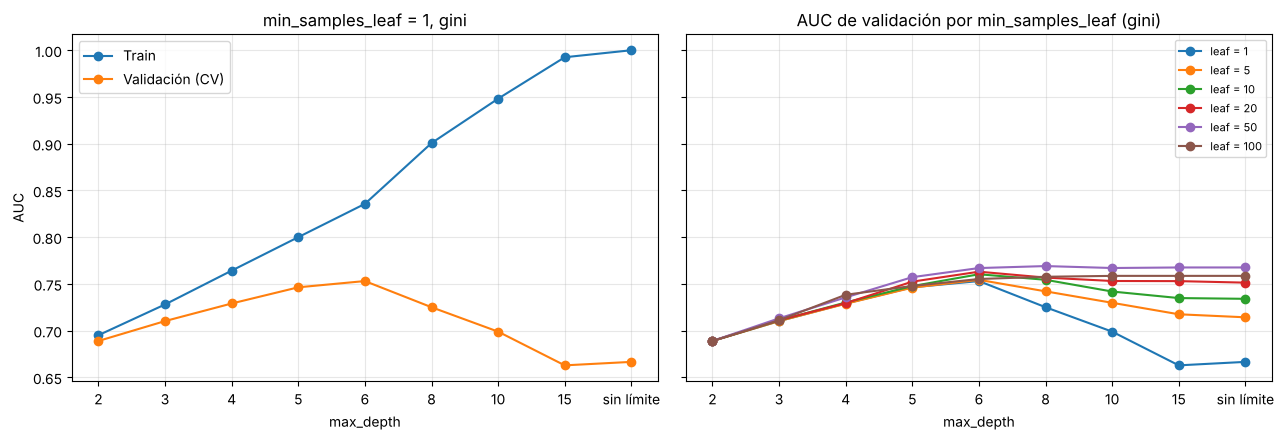

In [5]:
import matplotlib.pyplot as plt

orden = [str(d) for d in GRILLA['max_depth'][:-1]] + ['sin límite']
g = grilla.assign(max_depth=grilla['max_depth'].astype(str))
g['max_depth'] = pd.Categorical(g['max_depth'], categories=orden, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

hoja1 = g[(g['min_samples_leaf'] == 1) & (g['criterion'] == 'gini')].sort_values('max_depth')
axes[0].plot(hoja1['max_depth'].astype(str), hoja1['auc_train'], 'o-', label='Train')
axes[0].plot(hoja1['max_depth'].astype(str), hoja1['auc'], 'o-', label='Validación (CV)')
axes[0].set_title('min_samples_leaf = 1, gini')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('AUC')
axes[0].legend()
axes[0].grid(alpha=0.3)

for hoja in GRILLA['min_samples_leaf']:
    sub = g[(g['min_samples_leaf'] == hoja) & (g['criterion'] == 'gini')].sort_values('max_depth')
    axes[1].plot(sub['max_depth'].astype(str), sub['auc'], 'o-', label=f'leaf = {hoja}')
axes[1].set_title('AUC de validación por min_samples_leaf (gini)')
axes[1].set_xlabel('max_depth')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.4 Mejor configuración

Se elige la combinación con **mayor AUC de validación**. Si hay otras dentro de un desvío estándar, se muestran para considerar la más simple (menos profunda o con hojas más grandes) y la de menor distancia entre train y validación.

In [6]:
mejor = grilla.iloc[0]
print('Mejor árbol:')
print(f"  max_depth={mejor['max_depth']}, min_samples_leaf={mejor['min_samples_leaf']}, criterion={mejor['criterion']}")
print(f"  AUC validación = {mejor['auc']:.3f} ± {mejor['auc_std']:.3f}")
print(f"  AUC train      = {mejor['auc_train']:.3f}  (diferencia {mejor['auc_train'] - mejor['auc']:.3f})")
print(f"  Mejora sobre el baseline: +{mejor['auc'] - baseline['auc']:.3f} de AUC")

empatadas = grilla[grilla['auc'] >= mejor['auc'] - mejor['auc_std']]
print(f"\nCombinaciones dentro de un desvío del mejor: {len(empatadas)} (se muestran las 10 primeras)")
empatadas.head(10)[COLS_TABLA].assign(diferencia_train_val=empatadas['auc_train'].head(10) - empatadas['auc'].head(10)).round(3)

Mejor árbol:
  max_depth=8, min_samples_leaf=50, criterion=gini
  AUC validación = 0.769 ± 0.013
  AUC train      = 0.813  (diferencia 0.044)
  Mejora sobre el baseline: +0.103 de AUC

Combinaciones dentro de un desvío del mejor: 24 (se muestran las 10 primeras)


,max_depth,min_samples_leaf,criterion,auc,auc_std,auc_train,accuracy,precision,recall,f1,diferencia_train_val
0,8,50,gini,0.769,0.013,0.813,0.697,0.705,0.669,0.685,0.044
1,sin límite,50,gini,0.768,0.012,0.819,0.693,0.695,0.677,0.685,0.051
2,15,50,gini,0.768,0.012,0.819,0.693,0.695,0.677,0.685,0.051
3,10,50,gini,0.767,0.010,0.817,0.693,0.695,0.677,0.685,0.050
4,6,50,gini,0.767,0.009,0.803,0.704,0.724,0.648,0.684,0.036
5,8,50,entropy,0.767,0.015,0.814,0.699,0.703,0.678,0.690,0.047
6,6,50,entropy,0.764,0.012,0.802,0.699,0.722,0.638,0.677,0.037
7,10,50,entropy,0.764,0.014,0.818,0.696,0.699,0.677,0.688,0.054
8,15,50,entropy,0.764,0.015,0.819,0.696,0.699,0.677,0.688,0.055
9,sin límite,50,entropy,0.764,0.015,0.819,0.696,0.699,0.677,0.688,0.055


**Elección:** `max_depth=8`, `min_samples_leaf=50`, `criterion=gini`. Tiene el mayor AUC de validación (0,769 ± 0,013) y una diferencia train/validación baja (0,044). Las primeras combinaciones están todas dentro de un desvío entre sí y comparten `min_samples_leaf=50`: lo que más importa es el tamaño mínimo de hoja, no la profundidad ni el criterio. La de `max_depth=6` tiene una diferencia train/validación algo menor (0,036) con AUC 0,767, también sería una elección razonable; se mantiene la de mayor AUC.

## 5. Análisis del árbol elegido

Se reconstruye el mejor árbol de la grilla y se analiza: matriz de confusión (con las predicciones de validación de la CV), importancia de variables y las primeras reglas del árbol.

In [7]:
params_mejor = {
    'max_depth': None if mejor['max_depth'] == 'sin límite' else int(mejor['max_depth']),
    'min_samples_leaf': int(mejor['min_samples_leaf']),
    'criterion': mejor['criterion'],
}
mejor_arbol = DecisionTreeClassifier(**params_mejor, random_state=SEED)
mejor_arbol

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

### 5.1 Matriz de confusión

Cada película se predice con el modelo del fold en el que quedó en validación (o sea, con un modelo que no la vio al entrenar). Se usa el umbral por defecto de 0,5 sobre la probabilidad.

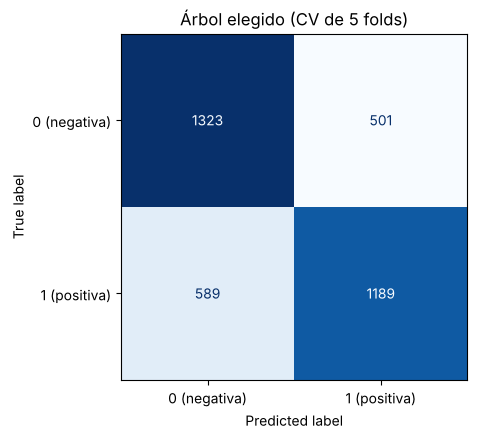

Verdaderos negativos: 1323  | Falsos positivos: 501
Falsos negativos:     589  | Verdaderos positivos: 1189
De las películas con opinión positiva, detecta el 67% (recall)
De las que predice como positivas, acierta el 70% (precision)


In [8]:
fig, ax = plt.subplots(figsize=(5, 4.5))
cm = matriz_confusion(mejor_arbol, X, y, titulo='Árbol elegido (CV de 5 folds)', ax=ax)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Verdaderos negativos: {tn}  | Falsos positivos: {fp}')
print(f'Falsos negativos:     {fn}  | Verdaderos positivos: {tp}')
print(f'De las películas con opinión positiva, detecta el {tp / (tp + fn):.0%} (recall)')
print(f'De las que predice como positivas, acierta el {tp / (tp + fp):.0%} (precision)')

### 5.2 Importancia de variables

Se entrena el árbol con todo el train y se mira cuánto reduce la impureza cada variable en total (`feature_importances_`). Las variables que no aparecen no se usaron en ningún corte.

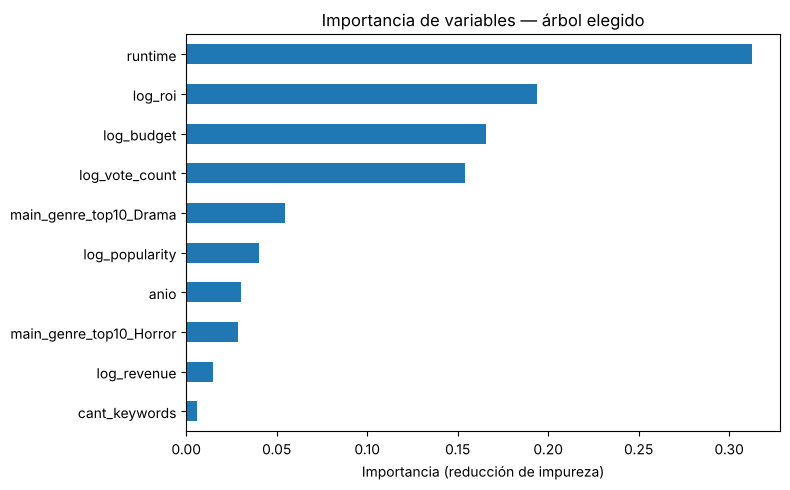

Variables usadas: 10 de 27
Profundidad real: 8 | Hojas: 46


runtime                    0.312
log_roi                    0.194
log_budget                 0.166
log_vote_count             0.154
main_genre_top10_Drama     0.054
log_popularity             0.040
anio                       0.030
main_genre_top10_Horror    0.029
log_revenue                0.015
cant_keywords              0.006
dtype: float64

In [9]:
pipe_mejor = entrenar(mejor_arbol, X, y)
nombres = pipe_mejor.named_steps['prep'].get_feature_names_out()
importancias = (pd.Series(pipe_mejor.named_steps['modelo'].feature_importances_, index=nombres)
                .sort_values(ascending=False))

top = importancias[importancias > 0].head(15)
fig, ax = plt.subplots(figsize=(8, 5))
top.sort_values().plot.barh(ax=ax)
ax.set_title('Importancia de variables — árbol elegido')
ax.set_xlabel('Importancia (reducción de impureza)')
plt.tight_layout()
plt.show()

print(f'Variables usadas: {(importancias > 0).sum()} de {len(importancias)}')
print(f'Profundidad real: {pipe_mejor.named_steps["modelo"].get_depth()} | '
      f'Hojas: {pipe_mejor.named_steps["modelo"].get_n_leaves()}')
importancias.head(10).round(3)

### 5.3 Primeras reglas del árbol

Se muestran los 3 primeros niveles. En cada nodo: la regla de corte, la impureza (gini), la cantidad de películas, cuántas hay de cada clase y la clase mayoritaria (el color indica la clase y su intensidad, qué tan pura es). Los valores numéricos están **escalados** (`StandardScaler`), así que un corte en 0 corresponde aproximadamente al promedio de esa variable.

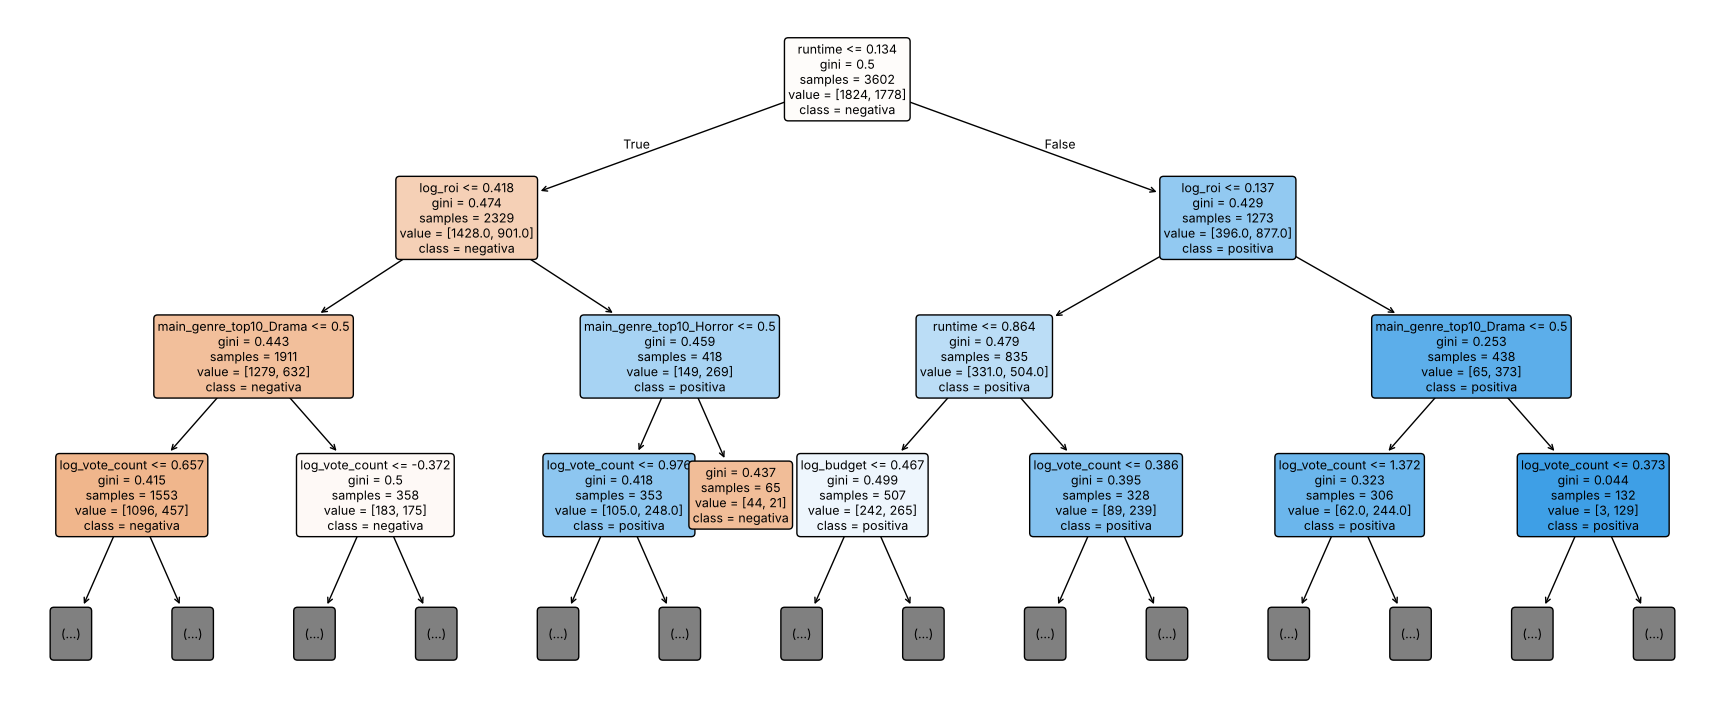

In [10]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(pipe_mejor.named_steps['modelo'], max_depth=3, feature_names=list(nombres),
          class_names=['negativa', 'positiva'], filled=True, rounded=True, impurity=True,
          proportion=False, fontsize=9, ax=ax)

plt.show()

## 6. Submission y resultado en Kaggle

Se entrena el árbol elegido con **todo** el train y se guardan las **probabilidades** de la clase 1 para las 1201 películas del test (no clases 0/1, porque la métrica de la competencia es AUC). El archivo queda en `kaggle/submission_arbol.csv`.

In [11]:
sub = generar_submission(mejor_arbol, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_arbol.csv')

# Chequeos: 1201 filas, sin NaN y probabilidades (no solo 0/1)
assert len(sub) == len(X_test) and sub['opinion'].notna().all()
print(f"Probabilidades entre {sub['opinion'].min():.3f} y {sub['opinion'].max():.3f}, "
      f"{sub['opinion'].nunique()} valores distintos")
sub.head()

Guardado kaggle/submission_arbol.csv (1201 filas)
Probabilidades entre 0.022 y 1.000, 44 valores distintos


,id,opinion
0,0,0.872727
1,1,0.716418
2,2,1.000000
3,3,0.872727
4,4,0.716418


### Resultado en Kaggle

*Public Score* obtenido al subir `kaggle/submission_arbol.csv`. La fila se guarda en `resultados/Arbol_Clasificacion/arbol_final.csv` para la tabla comparativa entre modelos.

In [12]:
auc_kaggle = 0.77058  # Public Score de Kaggle

resultado_final = {
    'modelo': 'Árbol de clasificación',
    'hiperparametros': f"max_depth={params_mejor['max_depth']}, min_samples_leaf={params_mejor['min_samples_leaf']}, criterion={params_mejor['criterion']}",
    'auc_cv': mejor['auc'], 'auc_cv_std': mejor['auc_std'], 'auc_train': mejor['auc_train'],
    'accuracy': mejor['accuracy'], 'precision': mejor['precision'], 'recall': mejor['recall'], 'f1': mejor['f1'],
    'auc_kaggle': auc_kaggle,
}
pd.DataFrame([resultado_final]).to_csv(f'{CARPETA_RESULTADOS}/arbol_final.csv', index=False)
pd.DataFrame([resultado_final]).round(3)

,modelo,hiperparametros,auc_cv,auc_cv_std,auc_train,accuracy,precision,recall,f1,auc_kaggle
0,Árbol de clasificación,"max_depth=8, min_samples_leaf=50, criterion=gini",0.769,0.013,0.813,0.697,0.705,0.669,0.685,0.771


**Interpretación:** el AUC en Kaggle (0,771) es prácticamente igual al de la validación cruzada (0,769 ± 0,013), y queda dentro de su desvío. Esto indica que:

- La CV estimó bien el rendimiento del modelo sobre datos nuevos, así que es una base confiable para comparar y elegir modelos.
- El árbol elegido no está sobreajustado al train: generaliza al test igual que a los folds de validación.
- No hay indicios de diferencias entre el train y el test (el Public Score se calcula sobre una parte del test, así que es una señal, no una prueba).

Este es el resultado a superar con los próximos modelos (regresión logística, Random Forest, AdaBoost y Gradient Boosting).